<a href="https://colab.research.google.com/github/IvanMusila/tajirika/blob/ml%2Fforecasting/03_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tajirika — Notebook 3: Forecast, Runway & What-If

Builds the per-user forecasting pipeline. Outputs:
- `forecast_utils.py` — shared with the FastAPI backend (single source of truth)
- `forecast_<user>.pkl` — a fitted Prophet model saved to Drive

**Run order:** 1 → 10. Needs `transactions_labeled.csv` and `transactions_income.csv` from Notebook 1.

**Design decisions baked in:**
- Forecast and anomaly models are **per-user** — trained on that user's own history, not a shared model.
- **Cash-flow view** for runway: everything that leaves M-Pesa is counted, except `savings_deposit` (M-Shwari / Ziidi — your own money, still accessible). Loan repayments are included because they are real cash leaving your balance.
- **Rent is separated** from the daily series before fitting Prophet. A Ksh 20,000+ monthly spike would dominate the model and distort daily forecasts.
- **Cold-start fallback** is used when there is less than 8 weeks of history.

## Cell 1 — Install and imports

In [ ]:
!pip install prophet --quiet   # also installs cmdstanpy and pystan

import warnings, json, sys, importlib, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
from datetime import timedelta
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics
warnings.filterwarnings('ignore')

## Cell 2 — Mount Drive and paths

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE   = '/content/drive/MyDrive/Tajirika'
DATA_CSV     = f'{DRIVE_BASE}/data/transactions_labeled.csv'
INCOME_CSV   = f'{DRIVE_BASE}/data/transactions_income.csv'
MODEL_DIR    = f'{DRIVE_BASE}/models/forecast'
UTILS_FILE   = f'{MODEL_DIR}/forecast_utils.py'

Path(MODEL_DIR).mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Cell 3 — `forecast_utils.py` (shared with FastAPI)
This file is the single source of truth for the forecast logic. It is saved to Drive and copied unchanged into the backend. Training and serving always use the same code.

In [ ]:
FORECAST_UTILS = '''
# forecast_utils.py — shared between Colab (training) and FastAPI (serving).
# DO NOT edit one copy without updating the other.

import warnings, json, joblib
import numpy as np
import pandas as pd
from pathlib import Path
from prophet import Prophet

warnings.filterwarnings('ignore')

MIN_WEEKS_FOR_PROPHET = 8
RENT_THRESHOLD        = 8000
SAVINGS_TYPES         = {'savings_deposit'}

def build_daily_series(df, exclude_types=None):
    if exclude_types is None:
        exclude_types = SAVINGS_TYPES
    spend = df[
        df['is_debit'] &
        ~df['transaction_type'].isin(exclude_types)
    ].copy()
    spend['date'] = pd.to_datetime(spend['timestamp']).dt.date
    daily = (spend.groupby('date')['amount'].sum()
                  .reset_index()
                  .rename(columns={'date': 'ds', 'amount': 'y'}))
    daily['ds'] = pd.to_datetime(daily['ds'])
    full_range = pd.date_range(daily['ds'].min(), daily['ds'].max(), freq='D')
    daily = (daily.set_index('ds')
                  .reindex(full_range, fill_value=0)
                  .rename_axis('ds')
                  .reset_index())
    return daily

def split_large_payments(df, threshold=RENT_THRESHOLD):
    # Step 1: remove savings entirely from spend
    spend_df = df[
        df['is_debit'] &
        ~df['transaction_type'].isin(SAVINGS_TYPES)
    ].copy()
    # Step 2: any single payment >= threshold leaves the daily series,
    # regardless of category (handles Absa 140k, Cisco 45k, one-off large sends)
    is_large = spend_df['amount'] >= threshold
    return spend_df[~is_large].copy(), spend_df[is_large].copy()

def monthly_large_avg(large_df):
    if large_df.empty:
        return 0.0
    large_df = large_df.copy()
    # Only count non-invisible merchants that recur >= 2 times (i.e. rent)
    # Drops one-off large payments like Absa 140k and Cisco 45k
    recurring = large_df[
        ~large_df['category'].isin(['invisible'])
    ].groupby('merchant_id').filter(lambda x: len(x) >= 2)
    if recurring.empty:
        return 0.0
    recurring['month'] = pd.to_datetime(recurring['timestamp']).dt.to_period('M')
    return recurring.groupby('month')['amount'].sum().median()

def cold_start_summary(df, balance):
    daily = build_daily_series(df)
    if daily.empty or daily['y'].sum() == 0:
        return {'method': 'cold_start', 'runway_days': None,
                'daily_avg': 0, 'monthly_forecast': 0,
                'forecast_df': None, 'model': None,
                'message': 'No spend history yet.'}
    daily_avg = daily['y'].mean()
    runway    = int(balance / daily_avg) if daily_avg > 0 else 999
    return {
        'method':           'cold_start',
        'runway_days':      runway,
        'daily_avg':        round(daily_avg, 2),
        'monthly_forecast': round(daily_avg * 30, 2),
        'forecast_df':      None,
        'model':            None,
        'message':          f'Using trailing average ({len(daily)} days of history).',
    }

def fit_prophet(daily_df):
    m = Prophet(
        weekly_seasonality=True,
        yearly_seasonality=True,
        daily_seasonality=False,
        seasonality_mode='multiplicative',
        changepoint_prior_scale=0.01,
        changepoint_range=0.95,
        seasonality_prior_scale=10,
    )
    m.add_seasonality(name='monthly', period=30.5, fourier_order=5)
    m.fit(daily_df)
    return m

def make_forecast(model, periods=30):
    future   = model.make_future_dataframe(periods=periods, freq='D')
    forecast = model.predict(future)
    return forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].copy()

def compute_runway(balance, forecast_df, large_monthly_avg=0):
    daily_large = large_monthly_avg / 30
    cum = 0.0
    for i, row in enumerate(forecast_df.itertuples()):
        daily = max(float(row.yhat), 0) + daily_large
        cum  += daily
        if cum >= balance:
            return i + 1
    avg_daily = max(forecast_df['yhat'].clip(lower=0).mean(), 1)
    return int(balance / avg_daily)

def what_if(balance, forecast_df, tx_df, category, reduce_pct, large_monthly_avg=0):
    spend = tx_df[
        tx_df['is_debit'] &
        ~tx_df['transaction_type'].isin(SAVINGS_TYPES)
    ]
    if spend.empty or spend['amount'].sum() == 0:
        return compute_runway(balance, forecast_df, large_monthly_avg), 0
    cat_share = (
        spend[spend['category'] == category]['amount'].sum() /
        spend['amount'].sum()
    )
    reduction_factor = cat_share * (reduce_pct / 100)
    adj = forecast_df.copy()
    adj['yhat']       = adj['yhat']       * (1 - reduction_factor)
    adj['yhat_lower'] = adj['yhat_lower'] * (1 - reduction_factor)
    adj['yhat_upper'] = adj['yhat_upper'] * (1 - reduction_factor)
    new_runway = compute_runway(balance, adj, large_monthly_avg)
    monthly_forecast = max(forecast_df['yhat'].clip(lower=0).sum(), 0)
    saved_ksh = monthly_forecast * cat_share * (reduce_pct / 100)
    return new_runway, round(saved_ksh, 2)

def fit_user_forecast(df, balance, user_id='user'):
    regular_df, large_df = split_large_payments(df)

    # Exclude loan repayments and invisible transactions from the forecast series.
    # These are lumpy and unpredictable (Fuliza spikes, bank transfers).
    # Their monthly average is added back as a fixed daily cost in runway calc.
    forecast_df = regular_df[
        ~regular_df['transaction_type'].isin({'loan_repayment'}) &
        ~regular_df['category'].isin({'invisible'})
    ].copy()
    daily = build_daily_series(forecast_df)

    # Invisible + loan monthly avg (spread as fixed daily cost alongside rent)
    invis_monthly = regular_df[
        regular_df['transaction_type'].isin({'loan_repayment'}) |
        regular_df['category'].isin({'invisible'})
    ].copy()
    invis_monthly['month'] = pd.to_datetime(invis_monthly['timestamp']).dt.to_period('M')
    invisible_monthly_avg = float(invis_monthly.groupby('month')['amount'].sum().median())

    large_monthly = monthly_large_avg(large_df)
    total_fixed_monthly = large_monthly + invisible_monthly_avg
    model    = fit_prophet(daily)
    forecast = make_forecast(model, periods=30)
    runway   = compute_runway(balance, forecast.tail(30), total_fixed_monthly)
    daily_avg = max(forecast.tail(30)['yhat'].clip(lower=0).mean(), 0)
    monthly   = round(daily_avg * 30 + total_fixed_monthly, 2)

    return {
        'method':                'prophet',
        'runway_days':           runway,
        'daily_avg':             round(daily_avg, 2),
        'monthly_forecast':      monthly,
        'large_monthly_avg':     round(large_monthly, 2),
        'invisible_monthly_avg': round(invisible_monthly_avg, 2),
        'forecast_df':           forecast,
        'model':                 model,
        'message':               f'Prophet fitted on {len(daily)} days of history.',
        'user_id':               user_id,
    }
'''

Path(UTILS_FILE).write_text(FORECAST_UTILS)
print(f'Saved: {UTILS_FILE}')

if MODEL_DIR not in sys.path:
    sys.path.insert(0, MODEL_DIR)
import forecast_utils as fu
importlib.reload(fu)
print('forecast_utils loaded. Functions:', [f for f in dir(fu) if not f.startswith('_')])


Saved: /content/drive/MyDrive/Tajirika/models/forecast/forecast_utils.py
forecast_utils loaded. Functions: ['MIN_WEEKS_FOR_PROPHET', 'Path', 'Prophet', 'RENT_THRESHOLD', 'SAVINGS_TYPES', 'build_daily_series', 'cold_start_summary', 'compute_runway', 'fit_prophet', 'fit_user_forecast', 'joblib', 'json', 'make_forecast', 'monthly_large_avg', 'np', 'pd', 'split_large_payments', 'warnings', 'what_if']


In [ ]:
# Debug: confirm what version of forecast_utils is loaded
import inspect
src = inspect.getsource(fu.split_large_payments)
print(src)
print("\nUtils file on disk:")
print(open(UTILS_FILE).read()[800:1400])

def split_large_payments(df, threshold=RENT_THRESHOLD):
    # Step 1: remove savings entirely from spend
    spend_df = df[
        df['is_debit'] &
        ~df['transaction_type'].isin(SAVINGS_TYPES)
    ].copy()
    # Step 2: any single payment >= threshold leaves the daily series,
    # regardless of category (handles Absa 140k, Cisco 45k, one-off large sends)
    is_large = spend_df['amount'] >= threshold
    return spend_df[~is_large].copy(), spend_df[is_large].copy()


Utils file on disk:
'ds', 'amount': 'y'}))
    daily['ds'] = pd.to_datetime(daily['ds'])
    full_range = pd.date_range(daily['ds'].min(), daily['ds'].max(), freq='D')
    daily = (daily.set_index('ds')
                  .reindex(full_range, fill_value=0)
                  .rename_axis('ds')
                  .reset_index())
    return daily

def split_large_payments(df, threshold=RENT_THRESHOLD):
    # Step 1: remove savings entirely from spend
    spend_df = df[
        df['is_debit'] &
        ~df['transaction_t

## Cell 4 — Load data and inspect the daily spend series
Checks the split between regular daily spend and large payments (rent etc.).

In [ ]:
df = pd.read_csv(DATA_CSV, parse_dates=['timestamp'])
df['is_debit'] = df['is_debit'].astype(bool)

# Income file: tells us about savings returns so we can exclude them from balance
income_df = pd.read_csv(INCOME_CSV, parse_dates=['timestamp'])

# Regular vs large payments
regular_df, large_df = fu.split_large_payments(df)
daily = fu.build_daily_series(regular_df)

print(f"Total expense rows:        {len(df)}")
print(f"Regular rows (< Ksh {fu.RENT_THRESHOLD:,}): {len(regular_df)}")
print(f"Large rows   (>= Ksh {fu.RENT_THRESHOLD:,}): {len(large_df)}")
print(f"\nLarge payment summary:")
if not large_df.empty:
    print(large_df.groupby('merchant_name')['amount']
                  .agg(['count','sum','mean'])
                  .sort_values('sum', ascending=False)
                  .round(0))
print(f"\nAverage monthly spend on large payments: Ksh {fu.monthly_large_avg(large_df):,.0f}")
print(f"\nDaily series: {len(daily)} days "
      f"({daily['ds'].min().date()} → {daily['ds'].max().date()})")
print(f"Mean daily spend (excl. large): Ksh {daily['y'].mean():,.0f}")
print(f"Median:  Ksh {daily['y'].median():,.0f}")
print(f"Max:     Ksh {daily['y'].max():,.0f}")
print(f"Zero-spend days: {(daily['y'] == 0).sum()} ({(daily['y']==0).mean():.0%})")

Total expense rows:        5784
Regular rows (< Ksh 8,000): 5651
Large rows   (>= Ksh 8,000): 34

Large payment summary:
                                          count       sum      mean
merchant_name                                                      
Beech Properties (Rent)                      24  484600.0   20192.0
Absa Bank                                     1  140000.0  140000.0
Acacia Vale Properties                        7  137800.0   19686.0
Cisco Agencies Ltd All Stock Agrovet Kam      1   45000.0   45000.0
Grace Amoi                                    1   22000.0   22000.0

Average monthly spend on large payments: Ksh 20,500

Daily series: 1001 days (2024-01-04 → 2026-09-30)
Mean daily spend (excl. large): Ksh 1,148
Median:  Ksh 772
Max:     Ksh 8,796
Zero-spend days: 83 (8%)


## Cell 5 — Fit Prophet and plot the forecast
Uses roughly your last known balance. Update `CURRENT_BALANCE` to whatever your balance is now — the forecast itself does not change, only the runway calculation does.

Method:           prophet
Message:          Prophet fitted on 1001 days of history.
Runway:           1 days
Daily avg (ML):   Ksh 1,369
Monthly forecast: Ksh 67,570
Large (rent etc): Ksh 20,500 / month


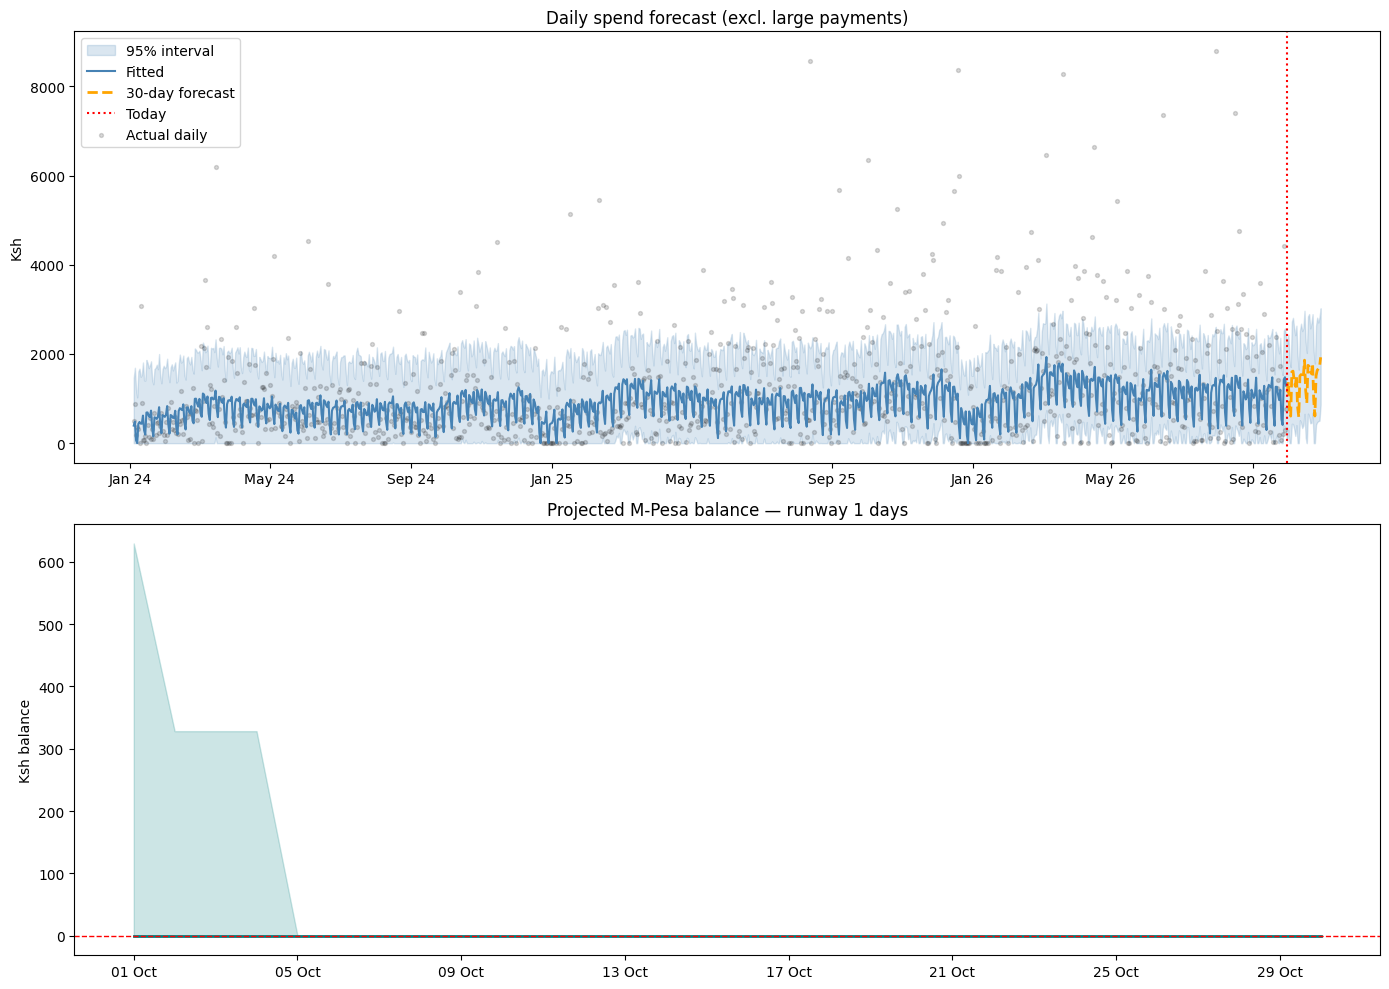

In [ ]:
# ── Update this to your current M-Pesa balance ────────────────────────────
CURRENT_BALANCE = 664.05   # Ksh  (from your most recent SMS)

result = fu.fit_user_forecast(df, balance=CURRENT_BALANCE, user_id='ivan')
print(f"Method:           {result['method']}")
print(f"Message:          {result['message']}")
print(f"Runway:           {result['runway_days']} days")
print(f"Daily avg (ML):   Ksh {result['daily_avg']:,.0f}")
print(f"Monthly forecast: Ksh {result['monthly_forecast']:,.0f}")
print(f"Large (rent etc): Ksh {result['large_monthly_avg']:,.0f} / month")

# ── Plot ──────────────────────────────────────────────────────────────────
forecast = result['forecast_df']
model    = result['model']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# Top: forecast with uncertainty
hist_end = pd.to_datetime(df['timestamp']).max()
hist  = forecast[forecast['ds'] <= hist_end]
fut   = forecast[forecast['ds'] >  hist_end]

ax1.fill_between(forecast['ds'], forecast['yhat_lower'].clip(0),
                 forecast['yhat_upper'].clip(0), alpha=0.2, color='steelblue', label='95% interval')
ax1.plot(hist['ds'], hist['yhat'].clip(0), color='steelblue', lw=1.5, label='Fitted')
ax1.plot(fut['ds'],  fut['yhat'].clip(0),  color='orange',    lw=2,   label='30-day forecast', linestyle='--')
ax1.axvline(hist_end, color='red', linestyle=':', lw=1.5, label='Today')

daily_plot = fu.build_daily_series(regular_df)
ax1.scatter(daily_plot['ds'], daily_plot['y'], alpha=0.15, s=8, color='black', label='Actual daily')
ax1.set_title('Daily spend forecast (excl. large payments)')
ax1.set_ylabel('Ksh')
ax1.legend(); ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))

# Bottom: balance trajectory over the 30-day window
fut_only = fut.head(30).copy()
fut_only['cum_spend']  = fut_only['yhat'].clip(0).cumsum()
fut_only['balance_lo'] = CURRENT_BALANCE - fut_only['yhat_upper'].clip(0).cumsum()
fut_only['balance']    = CURRENT_BALANCE - fut_only['cum_spend']
fut_only['balance_hi'] = CURRENT_BALANCE - fut_only['yhat_lower'].clip(0).cumsum()

ax2.fill_between(fut_only['ds'], fut_only['balance_lo'].clip(0),
                 fut_only['balance_hi'].clip(0), alpha=0.2, color='teal')
ax2.plot(fut_only['ds'], fut_only['balance'].clip(0), color='teal', lw=2)
ax2.axhline(0, color='red', linestyle='--', lw=1)
ax2.set_title(f'Projected M-Pesa balance — runway {result["runway_days"]} days')
ax2.set_ylabel('Ksh balance')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))

plt.tight_layout()
plt.savefig(f'{MODEL_DIR}/forecast_plot.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 6 — Prophet components (what drives spending patterns)

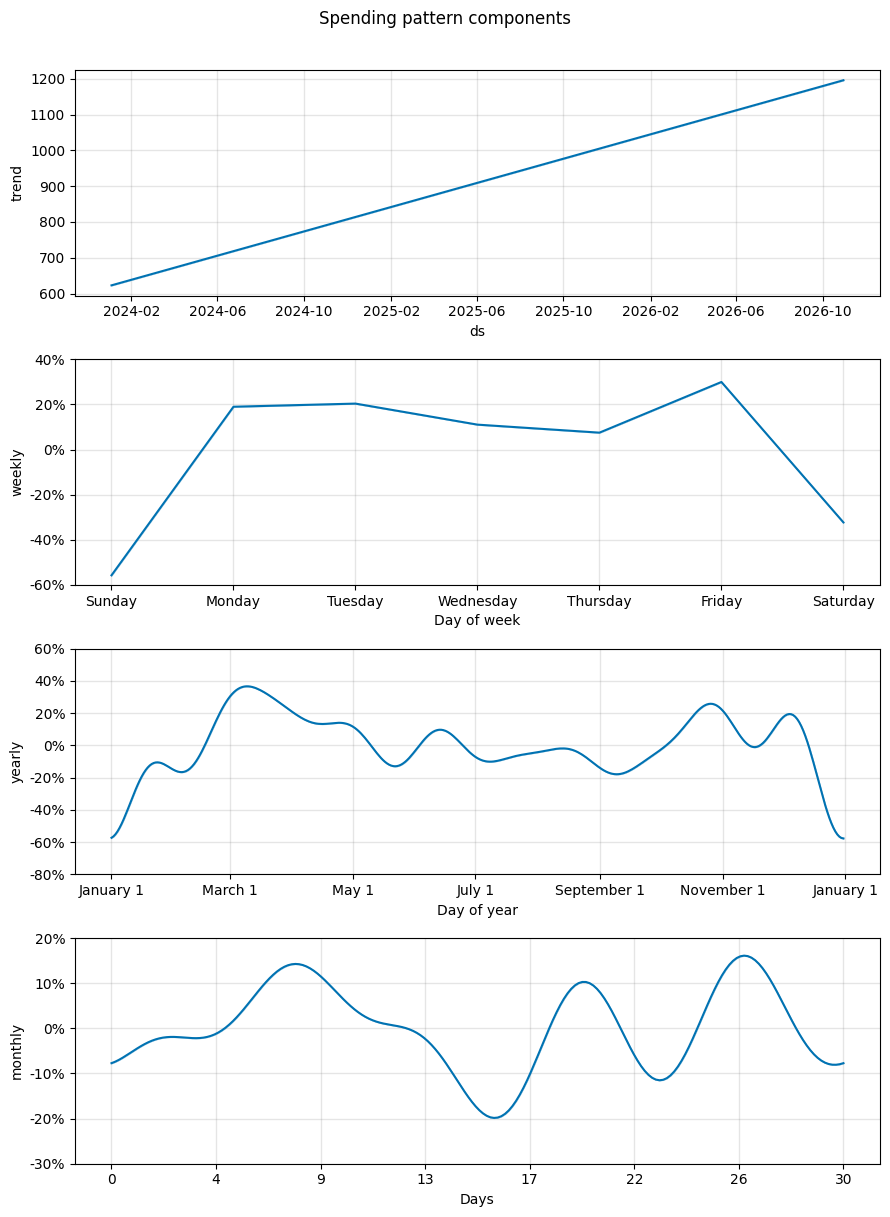


How to read these charts:
  Trend:   the slow drift in your spending over time
  Weekly:  which days of the week you spend most
  Yearly:  seasonal patterns (December spike?)
  Monthly: within-month patterns (end-of-month dip?)



In [ ]:
## Cell 6 — Prophet components (what drives spending patterns)
# make_forecast() returns only 4 columns; plot_components needs the full output
# so we re-run predict here to get trend, weekly, yearly etc.
future_full   = model.make_future_dataframe(periods=30, freq='D')
forecast_full = model.predict(future_full)

fig = model.plot_components(forecast_full)
plt.suptitle('Spending pattern components', y=1.01)
plt.tight_layout()
plt.savefig(f'{MODEL_DIR}/forecast_components.png', dpi=150, bbox_inches='tight')
plt.show()
print("""
How to read these charts:
  Trend:   the slow drift in your spending over time
  Weekly:  which days of the week you spend most
  Yearly:  seasonal patterns (December spike?)
  Monthly: within-month patterns (end-of-month dip?)
""")


## Cell 7 — What-if sliders
These numbers are what the Forecast screen in the app will show when the user drags a slider.

In [ ]:
forecast_30 = result['forecast_df'].tail(30)
large_monthly = result['large_monthly_avg']
base_runway   = result['runway_days']

print(f"Current balance:  Ksh {CURRENT_BALANCE:,.2f}")
print(f"Current runway:   {base_runway} days")
print(f"Monthly forecast: Ksh {result['monthly_forecast']:,.0f}")
print()
print(f"{'Category':<18} {'Reduce by':<12} {'New runway':<14} {'Save / month (Ksh)'}")
print("-" * 60)

for cat in ['convenience', 'social', 'aspirational', 'necessity']:
    for pct in [10, 20, 30]:
        new_rw, saved = fu.what_if(CURRENT_BALANCE, forecast_30, df, cat, pct, large_monthly)
        if saved > 0:
            print(f"{cat:<18} {pct}%{'':<10} {new_rw:<14} {saved:,.0f}")

Current balance:  Ksh 664.05
Current runway:   1 days
Monthly forecast: Ksh 67,570

Category           Reduce by    New runway     Save / month (Ksh)
------------------------------------------------------------
convenience        10%           1              495
convenience        20%           1              990
convenience        30%           1              1,485
social             10%           1              745
social             20%           1              1,490
social             30%           1              2,235
aspirational       10%           1              211
aspirational       20%           1              422
aspirational       30%           1              633
necessity          10%           1              1,846
necessity          20%           1              3,691
necessity          30%           1              5,536


## Cell 8 — Backtest: how good is the 30-day total and runway?
This is the honest evaluation. We train on data up to a cutoff, forecast 30 days forward, and compare to what actually happened. We test at several cutoffs and compare Prophet against two naive baselines.

Backtest periods: 5

    cutoff  actual_total  prophet_total  naive1_total  prophet_err_pct  naive1_err_pct
2026-04-19       43857.2        55644.6       58474.0             26.9            33.3
2026-05-17       45400.8        55243.5       45052.3             21.7             0.8
2026-06-14       42925.2        55710.7       35027.6             29.8            18.4
2026-07-12       44197.9        51238.7       41701.9             15.9             5.6
2026-08-09       52497.8        52698.4       40849.3              0.4            22.2

Mean absolute percentage error (30-day total spend):
  Prophet:        18.9%
  Trailing mean:  16.1%

Mean absolute error on runway (days):
  Prophet:       1.0 days
  Trailing mean: 0.0 days


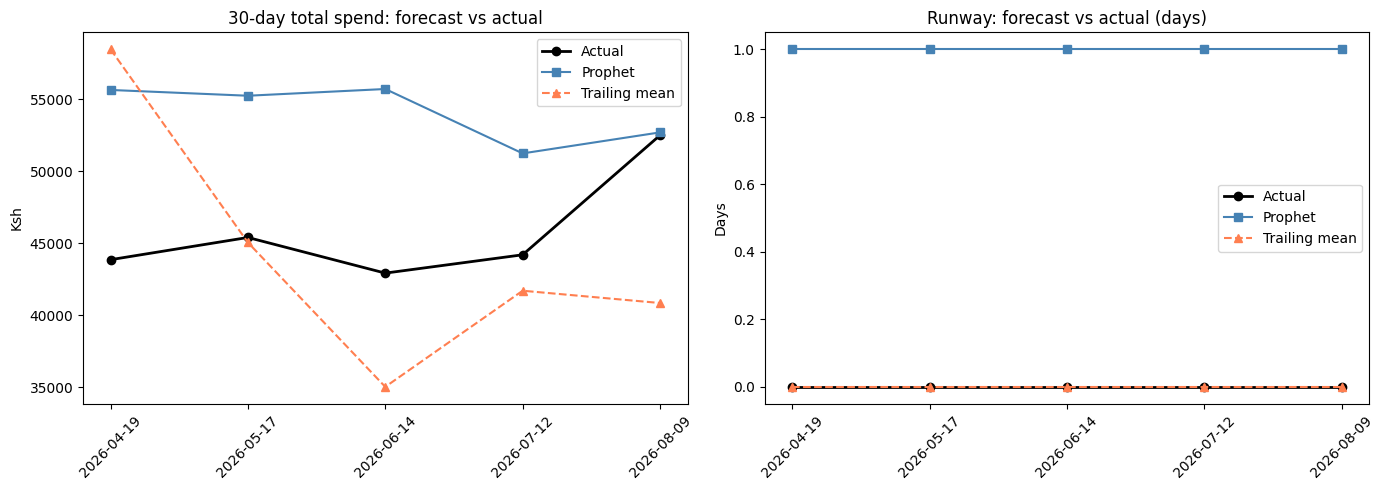

In [ ]:
def rolling_backtest(df, cutoffs_months=6, step_weeks=4):
    """
    For each cutoff: train Prophet up to that date, forecast 30 days,
    compare forecast total vs actual total and forecast runway vs actual runway.
    """
    regular, large = fu.split_large_payments(df)
    daily = fu.build_daily_series(regular)
    large_m = fu.monthly_large_avg(large)

    max_date  = daily['ds'].max()
    cutoff_start = max_date - pd.Timedelta(weeks=cutoffs_months * 4)
    cutoffs = pd.date_range(cutoff_start, max_date - pd.Timedelta(days=30), freq=f'{step_weeks}W')

    results = []
    for cutoff in cutoffs:
        train = daily[daily['ds'] <= cutoff]
        test  = daily[(daily['ds'] > cutoff) &
                      (daily['ds'] <= cutoff + pd.Timedelta(days=30))]
        if len(train) < 56 or test.empty:   # < 8 weeks
            continue

        actual_total = float(test['y'].sum())
        if actual_total == 0:
            continue

        # --- Prophet ---
        m = fu.fit_prophet(train)
        fc = fu.make_forecast(m, periods=30)
        fc30 = fc.tail(30)
        prophet_total = float(fc30['yhat'].clip(lower=0).sum())

        # --- Naive 1: trailing 30-day average ---
        naive1 = float(train.tail(30)['y'].mean()) * 30

        # --- Naive 2: same weekday same week last year ---
        # (fall back to 60-day mean if not enough history)
        try:
            same_period = train[(train['ds'] >= cutoff - pd.Timedelta(days=395)) &
                                (train['ds'] >= cutoff - pd.Timedelta(days=365))]
            naive2 = float(same_period['y'].mean()) * 30 if len(same_period) >= 14 else naive1
        except Exception:
            naive2 = naive1

        # Balance at cutoff = last known balance value from df
        bal = df[df['timestamp'] <= cutoff.to_pydatetime()]['balance'].iloc[-1] if \
              len(df[df['timestamp'] <= cutoff.to_pydatetime()]) > 0 else 0
        bal = float(bal)

        actual_runway  = int(bal / (actual_total / 30)) if actual_total > 0 else 999
        prophet_runway = fu.compute_runway(bal, fc30, large_m)
        naive1_runway  = int(bal / (naive1 / 30)) if naive1 > 0 else 999

        results.append({
            'cutoff':          cutoff.date(),
            'actual_total':    actual_total,
            'prophet_total':   prophet_total,
            'naive1_total':    naive1,
            'naive2_total':    naive2,
            'actual_runway':   actual_runway,
            'prophet_runway':  prophet_runway,
            'naive1_runway':   naive1_runway,
            'prophet_err_pct': abs(prophet_total - actual_total) / actual_total * 100,
            'naive1_err_pct':  abs(naive1 - actual_total) / actual_total * 100,
        })

    return pd.DataFrame(results)

bt = rolling_backtest(df)
print(f"Backtest periods: {len(bt)}")
print()
print(bt[['cutoff','actual_total','prophet_total','naive1_total',
          'prophet_err_pct','naive1_err_pct']].round(1).to_string(index=False))
print()
print("Mean absolute percentage error (30-day total spend):")
print(f"  Prophet:        {bt['prophet_err_pct'].mean():.1f}%")
print(f"  Trailing mean:  {bt['naive1_err_pct'].mean():.1f}%")
print()
print("Mean absolute error on runway (days):")
print(f"  Prophet:       {abs(bt['prophet_runway'] - bt['actual_runway']).mean():.1f} days")
print(f"  Trailing mean: {abs(bt['naive1_runway']  - bt['actual_runway']).mean():.1f} days")

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
x = range(len(bt))
ax1.plot(x, bt['actual_total'],  label='Actual', marker='o', color='black', lw=2)
ax1.plot(x, bt['prophet_total'], label='Prophet', marker='s', color='steelblue')
ax1.plot(x, bt['naive1_total'],  label='Trailing mean', marker='^', color='coral', linestyle='--')
ax1.set_title('30-day total spend: forecast vs actual'); ax1.set_ylabel('Ksh')
ax1.set_xticks(list(x)); ax1.set_xticklabels([str(c) for c in bt['cutoff']], rotation=45)
ax1.legend()

ax2.plot(x, bt['actual_runway'],  label='Actual', marker='o', color='black', lw=2)
ax2.plot(x, bt['prophet_runway'], label='Prophet', marker='s', color='steelblue')
ax2.plot(x, bt['naive1_runway'],  label='Trailing mean', marker='^', color='coral', linestyle='--')
ax2.set_title('Runway: forecast vs actual (days)'); ax2.set_ylabel('Days')
ax2.set_xticks(list(x)); ax2.set_xticklabels([str(c) for c in bt['cutoff']], rotation=45)
ax2.legend()

plt.tight_layout()
plt.savefig(f'{MODEL_DIR}/forecast_backtest.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 9 — Save the model and metadata

In [ ]:
from datetime import datetime

model_path = f'{MODEL_DIR}/forecast_ivan.pkl'
joblib.dump(result['model'], model_path)

meta = {
    'user_id':          'ivan',
    'trained_at':       datetime.now().isoformat(timespec='seconds'),
    'method':           result['method'],
    'history_days':     int(len(fu.build_daily_series(regular_df))),
    'runway_days':      result['runway_days'],
    'daily_avg':        result['daily_avg'],
    'monthly_forecast': result['monthly_forecast'],
    'large_monthly_avg': result['large_monthly_avg'],
    'current_balance':  CURRENT_BALANCE,
    'backtest': {
        'n_periods':             int(len(bt)),
        'mean_pct_err_total':    round(float(bt['prophet_err_pct'].mean()), 1),
        'mean_abs_err_runway':   round(float(abs(bt['prophet_runway'] - bt['actual_runway']).mean()), 1),
        'baseline_pct_err_total': round(float(bt['naive1_err_pct'].mean()), 1),
    } if len(bt) > 0 else {}
}
Path(f'{MODEL_DIR}/forecast_meta.json').write_text(json.dumps(meta, indent=2))

print("Saved:")
for f in [model_path, f'{MODEL_DIR}/forecast_meta.json',
          f'{MODEL_DIR}/forecast_utils.py',
          f'{MODEL_DIR}/forecast_plot.png',
          f'{MODEL_DIR}/forecast_backtest.png']:
    print("  ", f)
print()
print(json.dumps(meta, indent=2))

Saved:
   /content/drive/MyDrive/Tajirika/models/forecast/forecast_ivan.pkl
   /content/drive/MyDrive/Tajirika/models/forecast/forecast_meta.json
   /content/drive/MyDrive/Tajirika/models/forecast/forecast_utils.py
   /content/drive/MyDrive/Tajirika/models/forecast/forecast_plot.png
   /content/drive/MyDrive/Tajirika/models/forecast/forecast_backtest.png

{
  "user_id": "ivan",
  "trained_at": "2026-11-15T06:35:38",
  "method": "prophet",
  "history_days": 1001,
  "runway_days": 1,
  "daily_avg": 1368.63,
  "monthly_forecast": 67569.68,
  "large_monthly_avg": 20500.0,
  "current_balance": 664.05,
  "backtest": {
    "n_periods": 5,
    "mean_pct_err_total": 18.9,
    "mean_abs_err_runway": 1.0,
    "baseline_pct_err_total": 16.1
  }
}


## Cell 10 — Reload and verify (simulates FastAPI startup)
Loads the saved files exactly as the backend will, runs a forecast and what-if, and prints the JSON payload the `/forecast` endpoint will return.

In [ ]:
# Reload fresh
loaded_model = joblib.load(f'{MODEL_DIR}/forecast_ivan.pkl')
fc_fresh = fu.make_forecast(loaded_model, periods=30)
runway_fresh = fu.compute_runway(CURRENT_BALANCE, fc_fresh.tail(30),
                                 result['large_monthly_avg'])

# Example what-if: reduce convenience by 20%
new_rw, saved = fu.what_if(CURRENT_BALANCE, fc_fresh.tail(30), df,
                            'convenience', 20, result['large_monthly_avg'])

# The JSON the FastAPI /forecast endpoint will return
api_response = {
    'runway_days':        runway_fresh,
    'daily_avg_ksh':      round(float(fc_fresh.tail(30)['yhat'].clip(lower=0).mean()), 2),
    'monthly_forecast_ksh': round(float(fc_fresh.tail(30)['yhat'].clip(lower=0).sum()), 2),
    'large_monthly_ksh':  round(result['large_monthly_avg'], 2),
    'method':             'prophet',
    'forecast_series': [
        {'date': str(r.ds.date()), 'yhat': round(max(float(r.yhat), 0), 2),
         'yhat_lower': round(max(float(r.yhat_lower), 0), 2),
         'yhat_upper': round(max(float(r.yhat_upper), 0), 2)}
        for r in fc_fresh.tail(30).itertuples()
    ],
    'what_if_example': {
        'category': 'convenience',
        'reduce_pct': 20,
        'new_runway_days': new_rw,
        'saved_ksh_per_month': saved,
    }
}
print(json.dumps({k: v for k, v in api_response.items() if k != 'forecast_series'}, indent=2))
print(f"\nForecast series: {len(api_response['forecast_series'])} days")
print("First entry:", api_response['forecast_series'][0])
print("Last entry:",  api_response['forecast_series'][-1])
print("\nModel reloaded and verified. Ready for FastAPI integration.")

{
  "runway_days": 1,
  "daily_avg_ksh": 1368.63,
  "monthly_forecast_ksh": 41058.92,
  "large_monthly_ksh": 20500.0,
  "method": "prophet",
  "what_if_example": {
    "category": "convenience",
    "reduce_pct": 20,
    "new_runway_days": 1,
    "saved_ksh_per_month": 989.89
  }
}

Forecast series: 30 days
First entry: {'date': '2026-10-01', 'yhat': 1140.65, 'yhat_lower': 0, 'yhat_upper': 2235.17}
Last entry: {'date': '2026-10-30', 'yhat': 1925.92, 'yhat_lower': 865.01, 'yhat_upper': 3057.36}

Model reloaded and verified. Ready for FastAPI integration.


In [ ]:
# Find the Absa transaction date and check the daily series around it
absa = df[df['merchant_name'] == 'Absa Bank'].copy()
print("Absa transaction:")
print(absa[['timestamp', 'amount', 'transaction_type', 'category']])

# Check what the daily series looks like in the first backtest window
# (the Apr 19 cutoff covers roughly Jan-Apr 2026)
regular, large = fu.split_large_payments(df)
daily = fu.build_daily_series(regular)

print("\nTop 10 highest-spend days in the daily series:")
print(daily.nlargest(10, 'y')[['ds', 'y']])

print("\nDaily spend Apr 2026 (around first cutoff):")
apr = daily[(daily['ds'] >= '2026-03-01') & (daily['ds'] <= '2026-04-30')]
print(apr[apr['y'] > 2000])

print("\nWhat is the actual_total 43,857 made of?")
test_window = df[
    (df['timestamp'] >= '2026-04-19') &
    (df['timestamp'] <= '2026-05-19') &
    df['is_debit'] &
    ~df['transaction_type'].isin({'savings_deposit'}) &
    (df['amount'] < 8000)
]
print(f"Rows in test window: {len(test_window)}")
print(f"Total: Ksh {test_window['amount'].sum():,.0f}")
print("\nCategory breakdown:")
print(test_window.groupby('category')['amount'].sum().sort_values(ascending=False))
print("\nTop merchants in this window:")
print(test_window.groupby('merchant_name')['amount'].sum().sort_values(ascending=False).head(10))

Absa transaction:
               timestamp    amount transaction_type   category
3146 2025-08-13 12:48:38    1200.0          paybill  invisible
5089 2026-06-15 18:13:37  140000.0          paybill  invisible

Top 10 highest-spend days in the daily series:
            ds        y
939 2026-07-31  8796.26
587 2025-08-13  8574.00
715 2025-12-19  8359.00
806 2026-03-20  8284.05
956 2026-08-17  7398.43
893 2026-06-15  7360.43
833 2026-04-16  6638.85
792 2026-03-06  6471.39
637 2025-10-02  6345.53
71  2024-03-15  6185.00

Daily spend Apr 2026 (around first cutoff):
            ds        y
788 2026-03-02  2020.00
792 2026-03-06  6471.39
798 2026-03-12  2666.42
804 2026-03-18  2337.89
805 2026-03-19  2027.00
806 2026-03-20  8284.05
809 2026-03-23  2188.00
813 2026-03-27  3204.00
817 2026-03-31  3964.86
819 2026-04-02  3696.00
824 2026-04-07  2808.69
825 2026-04-08  3850.00
826 2026-04-09  2467.08
829 2026-04-12  2448.57
832 2026-04-15  4627.42
833 2026-04-16  6638.85
834 2026-04-17  2194.00
836 

In [ ]:
regular, large = fu.split_large_payments(df)
daily_all  = fu.build_daily_series(regular)

# Build a cleaner series excluding invisible and loan_repayment
clean = regular[~regular['transaction_type'].isin({'loan_repayment'}) &
                ~regular['category'].isin({'invisible'})]
daily_clean = fu.build_daily_series(clean)

print(f"Daily series (current): mean Ksh {daily_all['y'].mean():,.0f}, "
      f"median Ksh {daily_all['y'].median():,.0f}")
print(f"Daily series (clean):   mean Ksh {daily_clean['y'].mean():,.0f}, "
      f"median Ksh {daily_clean['y'].median():,.0f}")

print("\nWhat gets excluded:")
excluded = regular[regular['transaction_type'].isin({'loan_repayment'}) |
                   regular['category'].isin({'invisible'})]
print(excluded.groupby(['transaction_type','category'])['amount']
              .agg(['count','sum']).sort_values('sum', ascending=False))

Daily series (current): mean Ksh 1,148, median Ksh 772
Daily series (clean):   mean Ksh 899, median Ksh 620

What gets excluded:
                            count        sum
transaction_type category                   
loan_repayment   invisible    354  175296.61
paybill          invisible    110   59412.00
fee              invisible    970   11354.66
unknown          invisible     19    3749.00
buy_goods        invisible      1     250.00


In [ ]:
regular, large = fu.split_large_payments(df)

forecast_df = regular[
    ~regular['transaction_type'].isin({'loan_repayment'}) &
    ~regular['category'].isin({'invisible'})
].copy()
daily_clean = fu.build_daily_series(forecast_df)

print("Monthly spend on the CLEAN series (what Prophet trains on):")
daily_clean['month'] = daily_clean['ds'].dt.to_period('M')
monthly = daily_clean.groupby('month')['y'].sum()
print(monthly.tail(12))
print(f"\nMean: Ksh {monthly.mean():,.0f}")
print(f"Median: Ksh {monthly.median():,.0f}")
print(f"Last 6 months mean: Ksh {monthly.tail(6).mean():,.0f}")
print(f"Last 6 months median: Ksh {monthly.tail(6).median():,.0f}")

Monthly spend on the CLEAN series (what Prophet trains on):
month
2025-10    39734.09
2025-11    32783.44
2025-12    31590.05
2026-01    23601.43
2026-02    29747.33
2026-03    44087.52
2026-04    40363.74
2026-05    28191.10
2026-06    36801.53
2026-07    28451.76
2026-08    32153.35
2026-09    27775.65
Freq: M, Name: y, dtype: float64

Mean: Ksh 27,256
Median: Ksh 27,776
Last 6 months mean: Ksh 32,290
Last 6 months median: Ksh 30,303


---
## Optional — Cold-start demo
Shows what the app returns for a user with only 3 weeks of history (simulates a new user).

In [ ]:
three_weeks = df[df['timestamp'] >= df['timestamp'].max() - pd.Timedelta(weeks=3)].copy()
cs = fu.cold_start_summary(three_weeks, balance=CURRENT_BALANCE)
print("Cold-start result for a new user (3 weeks of history):")
for k, v in cs.items():
    if k not in ('forecast_df', 'model'):
        print(f"  {k}: {v}")

Cold-start result for a new user (3 weeks of history):
  method: cold_start
  runway_days: 0
  daily_avg: 1104.35
  monthly_forecast: 33130.39
  message: Using trailing average (22 days of history).
